In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import preprocess_audio

print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)

Project root: d:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted
Python: d:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted\.venv\Scripts\python.exe


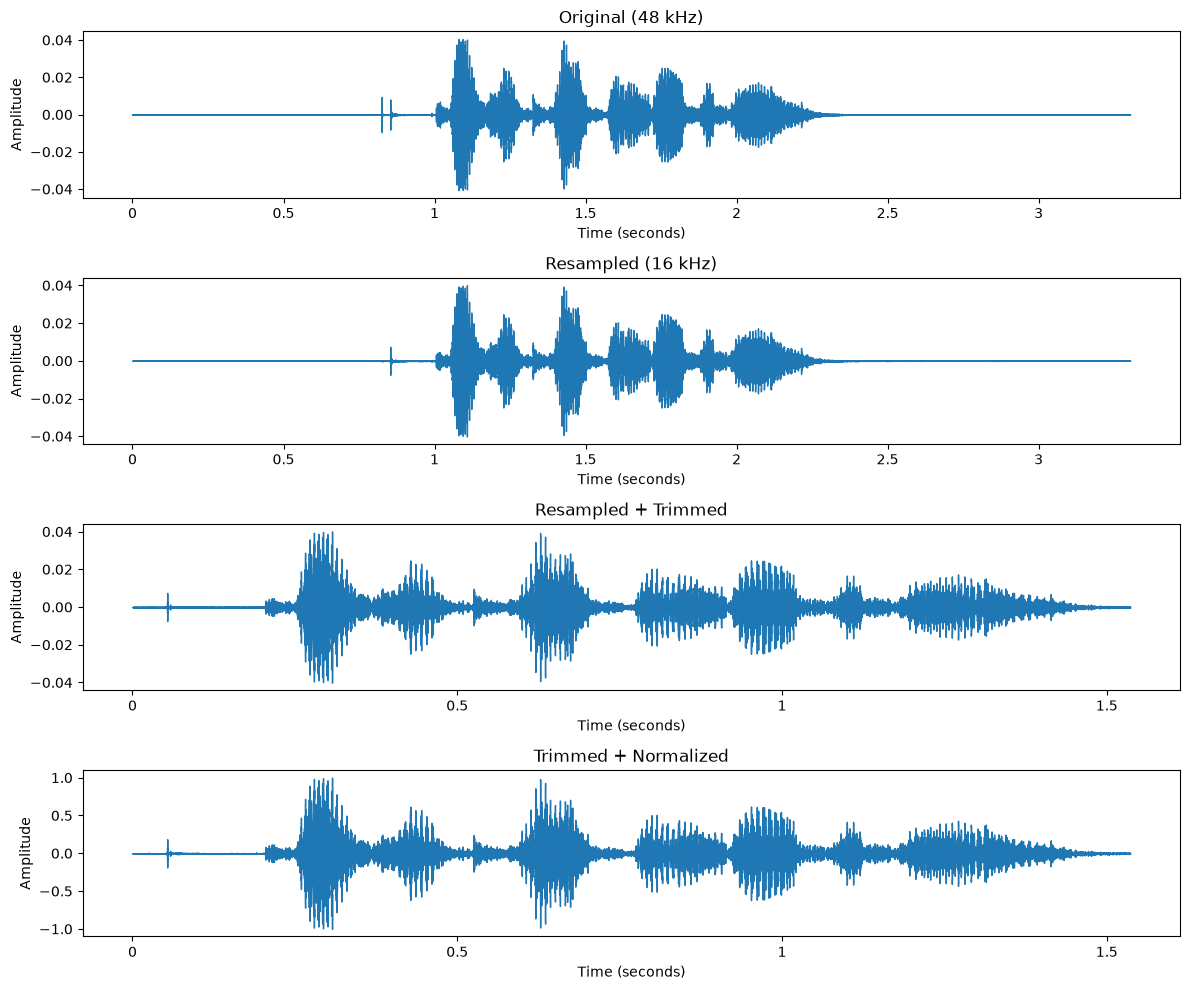

In [ ]:
# Visualize the four preprocessing stages

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

sample_file = (
    PROJECT_ROOT
    / "data/raw/Actor_01/03-01-01-01-01-01-01.wav"
)

# 1. Original recording
original, original_sr = librosa.load(
    sample_file, sr=None, mono=True
)

# 2. Resampled only
resampled, sr = preprocess_audio(
    sample_file, normalize=False, trim=False
)

# 3. Resampled + trimmed
trimmed, _ = preprocess_audio(
    sample_file, normalize=False, trim=True
)

# 4. Resampled + trimmed + normalized
processed, _ = preprocess_audio(sample_file)


signals = [
    (original, original_sr, "Original (48 kHz)"),
    (resampled, sr, "Resampled (16 kHz)"),
    (trimmed, sr, "Resampled + Trimmed"),
    (processed, sr, "Trimmed + Normalized"),
]


fig, axes = plt.subplots(4, 1, figsize=(12, 10))

for ax, (audio, sample_rate, title) in zip(axes, signals):
    librosa.display.waveshow(
        audio, sr=sample_rate, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [ ]:
# Compare durations and amplitudes

for audio, sample_rate, name in signals:
    duration = len(audio) / sample_rate
    peak = np.max(np.abs(audio))
    rms = np.sqrt(np.mean(audio**2))

    print(
        f"{name:25s} | "
        f"Duration: {duration:.2f}s | "
        f"Peak: {peak:.4f} | "
        f"RMS: {rms:.4f}"
    )

Original (48 kHz)         | Duration: 3.30s | Peak: 0.0406 | RMS: 0.0040
Resampled (16 kHz)        | Duration: 3.30s | Peak: 0.0401 | RMS: 0.0040
Resampled + Trimmed       | Duration: 1.54s | Peak: 0.0401 | RMS: 0.0059
Trimmed + Normalized      | Duration: 1.54s | Peak: 1.0000 | RMS: 0.1461


In [ ]:
# Listen to the original and trimmed recordings

from IPython.display import Audio, display

print("Original recording:")
display(Audio(original, rate=original_sr, normalize=False))

print("Trimmed recording:")
display(Audio(trimmed, rate=sr, normalize=False))

Original recording:


Trimmed recording:


In [ ]:
# Validate preprocessing across multiple emotions and actors

import pandas as pd
import numpy as np

metadata = pd.read_csv(PROJECT_ROOT / "data/metadata.csv")

# Select one recording per emotion
samples = (
    metadata.groupby("emotion_label", group_keys=False)
    .sample(n=1, random_state=42)
)

results = []

for _, row in samples.iterrows():
    file_path = PROJECT_ROOT / row["file_path"]

    original, original_sr = librosa.load(
        file_path, sr=None, mono=True
    )

    processed, processed_sr = preprocess_audio(
        file_path,
        normalize=False,
        trim=True,
    )

    original_duration = len(original) / original_sr
    processed_duration = len(processed) / processed_sr

    results.append({
        "emotion": row["emotion_label"],
        "actor_id": row["actor_id"],
        "original_duration": round(original_duration, 2),
        "processed_duration": round(processed_duration, 2),
        "retained_pct": round(
            100 * processed_duration / original_duration, 1
        ),
        "processed_peak": round(
            float(np.max(np.abs(processed))), 4
        ),
    })

results_df = pd.DataFrame(results)

display(results_df)

,emotion,actor_id,original_duration,processed_duration,retained_pct,processed_peak
0,angry,6,4.20,2.37,56.3,0.9815
1,calm,17,3.54,1.57,44.3,0.0420
2,disgust,7,4.77,2.98,62.4,0.0904
3,fearful,16,3.70,1.76,47.5,0.1611
4,happy,4,3.77,1.79,47.5,0.4493
5,neutral,7,4.14,2.08,50.3,0.0458
6,sad,8,3.77,1.98,52.6,0.0346
7,surprise,20,3.57,1.63,45.7,0.1192


In [7]:
# Validate all 1,440 recordings

from tqdm.auto import tqdm
import pandas as pd
import numpy as np

records = []

for _, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Validating audio"
):
    file_path = PROJECT_ROOT / row["file_path"]

    try:
        original, original_sr = librosa.load(
            file_path, sr=None, mono=True
        )

        processed, processed_sr = preprocess_audio(
            file_path,
            normalize=False,
            trim=True,
        )

        original_duration = len(original) / original_sr
        processed_duration = len(processed) / processed_sr

        records.append({
            "sample_id": row["sample_id"],
            "actor_id": row["actor_id"],
            "emotion": row["emotion_label"],
            "original_duration": original_duration,
            "processed_duration": processed_duration,
            "retained_pct": (
                100 * processed_duration / original_duration
            ),
            "processed_peak": float(
                np.max(np.abs(processed))
            ),
            "has_invalid_values": not np.isfinite(
                processed
            ).all(),
            "status": "success",
        })

    except Exception as e:
        records.append({
            "sample_id": row["sample_id"],
            "actor_id": row["actor_id"],
            "emotion": row["emotion_label"],
            "status": f"error: {e}",
        })

validation_df = pd.DataFrame(records)

print("Total files:", len(validation_df))
print("Successful:", (validation_df["status"] == "success").sum())
print("Failed:", (validation_df["status"] != "success").sum())

successful = validation_df[
    validation_df["status"] == "success"
]

display(
    successful[
        ["original_duration", "processed_duration", "retained_pct"]
    ].describe().round(2)
)

print("\nPotentially aggressive trimming (<30% retained):")

display(
    successful[successful["retained_pct"] < 30][
        ["sample_id", "emotion", "retained_pct"]
    ]
)

output_path = PROJECT_ROOT / "outputs/preprocessing_validation.csv"
validation_df.to_csv(output_path, index=False)

print(f"\nSaved: {output_path}")


d:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Validating audio: 100%|██████████| 1440/1440 [00:10<00:00, 139.52it/s]

Total files: 1440
Successful: 1440
Failed: 0


,original_duration,processed_duration,retained_pct
count,1440.00,1440.00,1440.00
mean,3.70,2.01,53.95
std,0.34,0.49,10.62
min,2.94,1.18,38.56
25%,3.47,1.66,47.11
50%,3.67,1.89,50.72
75%,3.87,2.24,57.10
max,5.27,4.31,100.00



Potentially aggressive trimming (<30% retained):


,sample_id,emotion,retained_pct



Saved: d:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted\outputs\preprocessing_validation.csv


In [8]:
print("Invalid recordings:",
      successful["has_invalid_values"].sum())

print("Zero-peak recordings:",
      (successful["processed_peak"] == 0).sum())

print("Very short recordings (<1 second):",
      (successful["processed_duration"] < 1).sum())

print("Lowest retention samples:")
display(
    successful.nsmallest(5, "retained_pct")[
        ["sample_id", "emotion", "processed_duration", "retained_pct"]
    ]
)

Invalid recordings: 0
Zero-peak recordings: 0
Very short recordings (<1 second): 0
Lowest retention samples:


,sample_id,emotion,processed_duration,retained_pct
1354,03-01-05-02-02-01-23,angry,1.248,38.559428
1135,03-01-08-01-02-02-19,surprise,1.184,38.569916
1359,03-01-06-01-02-02-23,fearful,1.216,39.186567
1338,03-01-03-02-02-01-23,happy,1.280,39.548132
652,03-01-08-01-01-01-11,surprise,1.216,39.612615
